In [ ]:
# Cella 1: Installazione dei pacchetti richiesti
!pip install pandas matplotlib seaborn nltk wordcloud scikit-learn

In [ ]:
# Cella 2: Importazione librerie e preparazione NLTK
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.sentiment import SentimentIntensityAnalyzer
from nltk.tokenize import word_tokenize

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from wordcloud import WordCloud

# Download risorse per NLTK
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('vader_lexicon')

print("Librerie e risorse caricate con successo!")

Librerie e risorse caricate con successo!


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


In [ ]:
# Cella 3: Generazione Dataset Ampliato (100 Prodotti)
import pandas as pd

data_ampliato = {
    'titolo_prodotto': [
        'Giacca in Pelle Biker', 'Cappotto Oversize Cashmere', 'T-shirt Basica Cotone Organic', 'Abito da Sera Seta Pure',
        'Jeans Slim Fit Denim', 'Borsa a Tracolla Lusso', 'Top Crop Unicolore', 'Maglia Lana Merino Extra-Fine',
        'Sneakers Casual Minimal', 'Vestito Elegante Pizzo', 'Piumino Leggero 100g', 'Orologio Automatico Acciaio',
        'Gonna Plissé Midi', 'Camicia Seta Sartoriale', 'Pantaloni Cargo Streetwear', 'Mocassini Pelle Lavorata',
        'Felpa Hooded Oversize', 'Trench Classico Sostenibile', 'Shorts Denim Unicolore', 'Scarpe decolleté Stiletto',
        'Cardigan Cotone Maglia', 'Cravatta Seta Jacquard', 'Leggings Sportivi Fit', 'Giacca Blazer Strutturata',
        'T-shirt Grafica Vintage', 'Borsa Shopper Canvas', 'Maglietta Polo Piqué', 'Cintura Pelle Fibbia Oro',
        'Pantaloni Chino Slim', 'Abito Corto Floreale', 'Parka Imbottito Freddo', 'Foulard Seta Stampato',
        'Sneakers High-Top Retro', 'Giachetto Vento Impermeabile', 'Maglioncino Collo Alto', 'Borsa Pochette Serale',
        'Tuta Sportiva Completa', 'Stivali Anfibi Pelle', 'Pantaloni Palazzo Fluido', 'Occhiali da Sole Design',
        'Gonna Mini Ecopelle', 'Giubbotto Denim Vintage', 'Top Seta Pizzo', 'Pantaloni Eleganti Righe',
        'Slipper Velluto Ricamato', 'T-shirt Scollo a V', 'Giacca Impermeabile Trench', 'Cappello Lana Beanie',
        'Borsa Zaffiano Strutturata', 'Sandali Cuoio Artigianali', 'Camicia Lino Fresco', 'Abito Wrap Vestito',
        'Piumino Lusso Pelliccia', 'Jeans Mom Fit Retro', 'Borsa Mini Tracolla', 'Maglia Dolcevita Cashmere',
        'Sneakers Running Performance', 'Vestito Tubino Classico', 'Canotta Cotone Ribbed', 'Giacca Scamosciata Fringe',
        'Pantaloni Jogger Fleece', 'Cintura Elasticizzata Casual', 'T-shirt Tinta Unita', 'Borsa Clutch Gioiello',
        'Scarpe Stringate Brogues', 'Gonna Longuette Maglia', 'Blazer Double Breasted', 'Cappotto Lana Strutturato',
        'Maglioncino Scollo V', 'Pantaloni Sartoriali Piega', 'Sandali Tacco Alto', 'Felpa Zip Cappuccio',
        'T-shirt Oversize Street', 'Borsa Tote Capiente', 'Mocassini Scamosciati Soft', 'Anfibi Platform Grintosi',
        'Abito Maxi Estivo', 'Giacca Bomber Satin', 'Pantaloni Skinny Elasticizzati', 'Camicia Oxford Classica',
        'Top Monospalla Serale', 'Cardigan Lungo Maglia', 'Borsone Viaggio Pelle', 'Sneakers Chunky Trendy',
        'Vestito Midi Georgette', 'Piumino Lungo Sostenibile', 'Gonna Ruota Cotone', 'Maglia Pura Seta Fine',
        'T-shirt Taschino Casual', 'Jeans Straight Leg', 'Borsa Shoulder Bag Lusso', 'Stivaletti Camoscio Tacco',
        'Cappello Tesa Larga', 'Giacca Varsity College', 'Pantaloni Lino Ampia', 'T-shirt Polo Righe',
        'Abito Blazer Doppio Petto', 'Cintura Sottile Pelle', 'Sneakers Slip-On Comode', 'Borsa Zaino Urban'
    ],
    'categoria': [
        'Fast Fashion', 'Luxury', 'Fast Fashion', 'Luxury', 'Fast Fashion', 'Luxury', 'Fast Fashion', 'Luxury',
        'Fast Fashion', 'Luxury', 'Fast Fashion', 'Luxury', 'Fast Fashion', 'Luxury', 'Fast Fashion', 'Luxury',
        'Fast Fashion', 'Luxury', 'Fast Fashion', 'Luxury', 'Fast Fashion', 'Luxury', 'Fast Fashion', 'Luxury',
        'Fast Fashion', 'Fast Fashion', 'Fast Fashion', 'Luxury', 'Fast Fashion', 'Fast Fashion', 'Fast Fashion', 'Luxury',
        'Fast Fashion', 'Fast Fashion', 'Luxury', 'Luxury', 'Fast Fashion', 'Luxury', 'Fast Fashion', 'Luxury',
        'Fast Fashion', 'Fast Fashion', 'Luxury', 'Luxury', 'Luxury', 'Fast Fashion', 'Fast Fashion', 'Fast Fashion',
        'Luxury', 'Luxury', 'Fast Fashion', 'Fast Fashion', 'Luxury', 'Fast Fashion', 'Luxury', 'Luxury',
        'Fast Fashion', 'Luxury', 'Fast Fashion', 'Luxury', 'Fast Fashion', 'Fast Fashion', 'Fast Fashion', 'Luxury',
        'Luxury', 'Fast Fashion', 'Luxury', 'Luxury', 'Fast Fashion', 'Luxury', 'Luxury', 'Fast Fashion',
        'Fast Fashion', 'Fast Fashion', 'Fast Fashion', 'Fast Fashion', 'Fast Fashion', 'Fast Fashion', 'Fast Fashion', 'Fast Fashion',
        'Luxury', 'Fast Fashion', 'Luxury', 'Fast Fashion', 'Luxury', 'Fast Fashion', 'Fast Fashion', 'Luxury',
        'Fast Fashion', 'Fast Fashion', 'Luxury', 'Fast Fashion', 'Luxury', 'Fast Fashion', 'Fast Fashion', 'Fast Fashion',
        'Luxury', 'Fast Fashion', 'Fast Fashion', 'Fast Fashion'
    ],
    'prezzo': [
        49.99, 1200.00, 12.99, 850.00, 29.99, 1500.00, 9.99, 320.00, 39.99, 680.00,
        59.99, 2100.00, 24.99, 450.00, 34.99, 520.00, 25.99, 890.00, 19.99, 610.00,
        22.99, 180.00, 15.99, 750.00, 14.99, 19.99, 27.99, 290.00, 39.99, 29.99,
        79.99, 310.00, 49.99, 34.99, 260.00, 950.00, 45.99, 480.00, 32.99, 410.00,
        21.99, 54.99, 280.00, 390.00, 620.00, 11.99, 69.99, 12.99, 1150.00, 340.00,
        29.99, 35.99, 1850.00, 39.99, 780.00, 420.00, 49.99, 590.00, 8.99, 980.00,
        22.99, 14.99, 9.99, 1300.00, 460.00, 27.99, 820.00, 1100.00, 29.99, 370.00,
        530.00, 31.99, 17.99, 39.99, 310.00, 59.99, 38.99, 44.99, 28.99, 32.99,
        490.00, 26.99, 1650.00, 55.99, 720.00, 89.99, 23.99, 380.00, 13.99, 36.99,
        1400.00, 240.00, 160.00, 64.99, 31.99, 25.99, 870.00, 18.99, 29.99, 33.99
    ],
    'descrizione_brand': [
        "Giacca alla moda in ecopelle grintosa, perfetta per outfit casual e serate informali. Design giovane e pratico.",
        "Raffinato cappotto sartoriale in pregiato cashmere sostenibile. Eleganza intramontabile, taglio artigianale e morbidezza esclusiva.",
        "T-shirt essenziale di cotone. Semplice, versatile e ideale per ogni giorno.",
        "Abito da sera in purissima seta italiana. Drappeggio sofisticato, design d'alta moda pensato per eventi esclusivi.",
        "Jeans elasticizzati con vestibilità moderna. Comodi, economici ed essenziali per il guardaroba quotidiano.",
        "Iconica borsa in pelle lavorata a mano. Un capolavoro di artigianalità, dettaglio dorato e lusso senza tempo.",
        "Top moderno ed economico per uno stile streetwear. Leggero e trendy.",
        "Maglione in pura lana merino dal tocco soffice. Stile raffinato per un'eleganza discreta e senza tempo.",
        "Scarpe da ginnastica versatili a prezzo accessibile. Design pulito da indossare sempre.",
        "Abito elegante con dettagli in pizzo prezioso. Silhouette d'impatto e maestria sartoriale d'alta classe.",
        "Piumino leggero e ripiegabile, pratico per il cambio stagione a costo contenuto.",
        "Orologio meccanico di alta orologeria con movimento automatico svizzero e dettagli curati.",
        "Gonna pieghettata alla moda, perfetta per un look dinamico e giovanile.",
        "Camicia in seta pura dal taglio impeccabile. Un capo lussuoso per ambienti formali.",
        "Pantaloni multitasche in cotone resistente, stile urbano ed economico.",
        "Mocassini in pelle pieno fiore con cuciture a mano, garanzia di classe ed eleganza.",
        "Felpa con cappuccio e vestibilità comoda, ottima per il relax quotidiano.",
        "Trench classico in tessuto tecnico impermeabile di altissima sartoria.",
        "Shorts di denim basici, fresco e indispensabile per l'estate.",
        "Scarpe col tacco in pelle pregiata, silhouette slanciata per occasioni speciali.",
        "Cardigan classico con bottoni, morbido e adatto a tutti i giorni.",
        "Cravatta in seta lavorata a telaio con motivi raffinati per un look distinto.",
        "Leggings contenitivi ed elasticizzati, perfetti per lo sport ed il tempo libero.",
        "Blazer doppiopetto strutturato in pura lana, taglio sartoriale per un look formale d'eccellenza.",
        "Maglietta a maniche corte con stampa vintage, giovanile ed economica.",
        "Borsa in tela resistente, capiente e pratica per la spesa o il mare.",
        "Polo basica in cotone traspirante, adatta per uno stile casual ordinato.",
        "Cintura in pelle pregiata con fibbia metallica dorata finitura lusso.",
        "Pantaloni chino eleganti e versatili, perfetti per l'ufficio ed il tempo libero.",
        "Abito corto estivo con motivo floreale fresco e vivace a prezzo accessibile.",
        "Parka con interno imbottito per proteggere dal freddo urbano, pratico ed economico.",
        "Foulard in seta con stampe artistiche esclusive, tocco di raffinatezza senza tempo.",
        "Sneakers alte in stile retrò, comode e di tendenza a costo contenuto.",
        "Giacca a vento leggera e idrorepellente, ideale per l'attività all'aperto.",
        "Maglia a collo alto in filato pregiato, caldo ed estremamente raffinato.",
        "Pochette da sera gioiello con tracolla a catena dorata, lusso da indossare.",
        "Tuta sportiva a due pezzi in cotone garzato, morbida ed economica.",
        "Stivali stile militare in vera pelle robusta, lavorazione artigianale d'eccellenza.",
        "Pantaloni a gamba larga in tessuto leggero, comodi ed eleganti per la stagione calda.",
        "Occhiali da sole con montatura artigianale e lenti ad alta protezione, design iconico.",
        "Mini gonna in ecopelle grintosa, perfetta per uscite serali e look moderni.",
        "Giubbotto in jeans lavaggio vintage, classico ed economico per la mezza stagione.",
        "Top romantico con inserti in pizzo e seta raffinata per uno stile femminile unico.",
        "Pantaloni gessati da sartoria, eleganza formale d'alta classe.",
        "Slipper sofisticate in velluto con ricamo fatto a mano, espressione di lusso discreto.",
        "T-shirt scollo V essenziale in cotone pettinato, economica e versatile.",
        "Trench impermeabile leggero per la pioggia, stile britannico pratico.",
        "Cappello in maglia calda per l'inverno, semplice e funzionale.",
        "Borsa rigida in pelle saffiano con dettagli dorati, un classico di lusso.",
        "Sandali estivi in cuoio naturale intrecciato a mano, tradizione artigianale.",
        "Camicia estiva in lino traspirante, fresca e informale.",
        "Abito con chiusura a portafoglio, pratico e adatto a varie fisicità.",
        "Piumino lungo con cappello in vera pelliccia sostenibile, calore ed esclusività.",
        "Jeans a vita alta stile anni '90, denim resistente ed economico.",
        "Piccola borsa a tracolla per essenziali, di alta moda e pelle morbida.",
        "Dolcevita in puro cashmere pettinato, calore avvolgente e qualità superiore.",
        "Scarpe da corsa ammortizzate con suola flessibile, ottime per l'allenamento.",
        "Tubino nero intramontabile dal taglio sartoriale perfetto per cerimonie.",
        "Canotta basica in cotone a costine, capo spalla semplice ed economico.",
        "Giacca in pelle scamosciata con frange, design d'ispirazione luxury bohémien.",
        "Pantaloni felpati con polsino alla caviglia, comfort casalingo e sportivo.",
        "Cintura intrecciata casual per jeans, regolabile e conveniente.",
        "T-shirt monocromatica in cotone leggero, capo fondamentale per il layering.",
        "Borsa da sera ricoperta di cristalli luminosi, lusso ed eleganza serale.",
        "Scarpe stringate maschili in pelle spazzolata, eleganza senza tempo.",
        "Gonna aderente in maglia elasticizzata, comoda ed economica.",
        "Giacca Blazer strutturata con bottoni dorati, eleganza formale d'alta moda.",
        "Cappotto lungo in misto lana pesante, taglio sartoriale d'impatto.",
        "Maglia leggera con scollo a V, semplice ed essenziale per tutti i giorni.",
        "Pantaloni con piega centrale in lana vergine, taglio sartoriale impeccabile.",
        "Sandali estivi con tacco alto e cinturino alla caviglia, lusso ed eleganza.",
        "Felpa con zip integrale, pratica per lo sport e le giornate informali.",
        "T-shirt con taglio ampio streetwear, giovane e conveniente.",
        "Borsa grande da giorno in ecopelle morbida, capiente ed economica.",
        "Mocassini scamosciati leggerissimi, comfort e stile casual quotidiano.",
        "Anfibi con suola alta e spessa, stile grintoso e di tendenza a costo contenuto.",
        "Abito lungo e leggero per l'estate, stampa fresca e giovanile.",
        "Giacca stile bomber in tessuto lucido satinato, economica e trendy.",
        "Pantaloni aderenti in tessuto molto elasticizzato, vestibilità comoda ed economica.",
        "Camicia formale in cotone Oxford, ideale per il lavoro quotidiano.",
        "Top elegante monospalla in seta, adatto per feste ed eventi esclusivi.",
        "Cardigan lungo e morbido senza bottoni, ideale per stare in casa o uscire.",
        "Borsone da viaggio in pelle pieno fiore, resistente e dal fascino lussuoso.",
        "Sneakers con suola oversize di tendenza, prezzo accessibile e stile moderno.",
        "Abito fluido in chiffon leggero con stampa delicata, sartoriale ed elegante.",
        "Piumino imbottito lungo fino al ginocchio, protezione totale ed economico.",
        "Gonna svasata in cotone leggero, fresca e versatile per il giorno.",
        "Maglietta sottogiacca in purissima seta, tocco delicato ed esclusivo.",
        "T-shirt basica con taschino frontale, dettagli semplici ed economici.",
        "Jeans taglio dritto classico, denim resistente a prezzo modico.",
        "Borsa a spalla in pelle matelassé, dettaglio catena e lusso sfrenato.",
        "Stivaletti in camoscio con tacco comodo, stile elegante e ben rifinito.",
        "Cappello a tesa larga per la protezione solare, stile estivo ed economico.",
        "Giacca stile college con maniche a contrasto, giovanile ed economica.",
        "Pantaloni ampi in lino per giornate calde, comfort e freschezza a buon prezzo.",
        "T-shirt stile polo a righe colorate, casual ed economica.",
        "Vestito blazer a doppio petto, stile manageriale raffinato d'alta classe.",
        "Cintura sottile in pelle per abiti e pantaloni, basica ed economica.",
        "Scarpe senza lacci comode da infilare, ideali per lunghe camminate quotidiane.",
        "Zaino urbano capiente con scomparto pc, pratico per studenti ed economici."
    ],
    'recensione_utente': [
        "Carina e di tendenza per quello che costa. La pelle sintetica è okay.",
        "Qualità eccelsa, la stoffa è incredibilmente morbida. Un investimento di classe vero.",
        "Maglietta basica senza troppe pretese, fa il suo dovere quotidiano.",
        "Stupendo! La seta brilla ed è tagliato magnificamente. Elegante e raffinato.",
        "Buona vestibilità ma il materiale dopo un po' perde forma. Prezzo onesto.",
        "Semplicemente perfetta. Dettagli curati nei minimi particolari, un sogno.",
        "Semplice, giovanile, va bene per un look veloce.",
        "Ottimo capo, calda e finitura sartoriale impagabile. Vale ogni euro.",
        "Comode per camminare, qualità proporzionata al prezzo contenuto.",
        "Veramente bellissimo, la fattura del pizzo è spettacolare e lussuosa.",
        "Molto leggero, non tiene caldissimo ma va bene per la primavera. Economico.",
        "Un pezzo d'arte al polso, precisione impeccabile e materiali di prim'ordine.",
        "Gonna carina, il tessuto è leggermente sintetico ma la piega tiene bene.",
        "Seta di altissimo livello, si sente la qualità artigianale al tatto. Bellissima.",
        "Molto pratici con tante tasche, vestibilità abbondante. Buono il prezzo.",
        "Mocassini comodissimi fin dal primo giorno, pelle morbida e classe pura.",
        "La felpa è comoda ma il cotone è un po' sottile. Va bene per stare in casa.",
        "Trench da sogno, veste benissimo e l'impermeabilità è totale. Eccezionale.",
        "Pantaloncini semplici, ideali per la spiaggia. Rapporto qualità prezzo top.",
        "Tacco alto ma scarpa sorprendentemente stabile. Lusso vero per i piedi.",
        "Maglia semplice, dopo qualche lavaggio fa un po' di pallini ma il prezzo è basso.",
        "Setosità e motivi ricamati alla perfezione. Completa l'abito in modo eccellente.",
        "Aderenti e non trasparenti. Ottimi per andare in palestra senza spendere molto.",
        "Taglio maschile impeccabile, tessuto di lana pregiata che non si stropiccia.",
        "La stampa è molto bella, la t-shirt veste il giusto. Economica ed estiva.",
        "Capiente per fare la spesa, la tela sembra resistente. Semplice.",
        "Polo classica, tessuto un po' rigido al primo lavaggio ma accettabile.",
        "La fibbia risplende, la pelle è spessa e ben rifinita. Veramente di classe.",
        "Buona vestibilità, il colore è esattamente come in foto. Prezzo conveniente.",
        "Vestitino leggero e fresco, perfetto per le giornate calde di mare.",
        "Tiene abbastanza caldo, la cerniera potrebbe essere migliore ma dato il prezzo va bene.",
        "Colori vivaci e seta morbidissima. Un accessorio raffinato che si nota.",
        "Design retrò fantastico, calzano giuste e sono comode per tutti i giorni.",
        "Protegge bene dal vento, materiale leggerissimo. Ottimo per la corsa.",
        "Il collo alto veste benissimo, filato morbido che non pizzica. Qualità superba.",
        "Piccola ma ci sta il telefono e i trucchi. I dettagli dorati sono bellissimi.",
        "Morbida per il relax, dopo vari lavaggi rimane uguale. Buon acquisto economico.",
        "Stivali robusti, pelle d'altissima qualità. Un po' pesanti ma stupendi.",
        "Tessuto molto leggero e fresco, cade bene sui fianchi. Buon prezzo.",
        "Montatura leggera ed elegante, lenti riposanti per gli occhi. Ottimo brand.",
        "Molto aderente e giovanile, fa la sua figura per una serata informale.",
        "Il lavaggio del jeans è bello, un classico giubbotto che non passa mai di moda.",
        "Il pizzo sul bordo è rifinito meravigliosamente. Seta delicata e pregiata.",
        "Pantalone da ufficio perfetto, il tessuto cade diritto senza fare difetti.",
        "Comodissime come pantofole ma eleganti da gran sera. Un lusso unico.",
        "Maglietta basica semplice, cotone nella norma. Prezzo imbattibile.",
        "Fa il suo dovere contro la pioggia leggera. Design classico senza tempo.",
        "Scalda il giusto, un po' strettino per chi ha la testa grande.",
        "La pelle saffiano non si graffia mai. Borsa robusta ed elegatissima.",
        "Lavorazione del cuoio stupenda, si sente il profumo della vera pelle.",
        "Freschissima per l'estate, si stropiccia facilmente essendo lino ma ci sta.",
        "Molto comodo la chiusura incrociata, nasconde i difetti. Prezzo onesto.",
        "Piumino caldissimo e pelliccia folta e morbida. Capo di lusso assoluto.",
        "Modello di tendenza, il denim è abbastanza rigido ma veste bene.",
        "Piccola ma raffinata, la pelle è soffice e la tracolla è curata nei dettagli.",
        "Morbidezza incredibile, una coccola sulla pelle nei giorni freddi. Eccellente.",
        "Buona ammortizzazione per la corsa leggera, colori sgargianti e comode.",
        "Un tubino che ogni donna dovrebbe avere, veste come un guanto. Elegante.",
        "Canottiera semplice da mettere sotto le camicie, prezzo bassissimo.",
        "Le frange danno un movimento bellissimo. Pelle scamosciata di altissima classe.",
        "Tuta da casa molto confortevole, interno garzato morbido e caldo.",
        "Semplice, fa il suo dovere per stringere i pantaloni. Economica.",
        "Classica maglietta bianca, cotone leggero ma non trasparente. Prezzo ok.",
        "Brilla tantissimo di sera, un vero gioiellino da sfoggiare nelle feste.",
        "Scarpe formali di ottima fattura, pelle lucida ed elegante. Durature.",
        "Aderisce bene alla figura, materiale sintetico ma comodo e caldo.",
        "Eleganza senza tempo, bottoni dorati molto luminosi e taglio perfetto.",
        "Caldo e avvolgente, la lana è di ottima qualità. Taglio lungo elegante.",
        "Semplice maglioncino da tutti i giorni, scollo V discreto. Buon Prezzo.",
        "Vestibilità sartoriale impeccabile, la piega rimane sempre perfetta.",
        "Tacco alto ma calzata confortevole, cinturino elegante alla caviglia.",
        "Pratica da buttare sopra quando si va in palestra. Cotone semplice.",
        "Taglio ampio e moderno, piacevole da indossare con i jeans. Economica.",
        "Borsa capiente per metterci di tutto, materiale plastico ma resistente.",
        "Sembra di camminare sulle nuvole, camoscio morbidissimo. Ottimo acquisto.",
        "Suola alta che dà qualche centimetro in più, grintosi e giovanili.",
        "Abito estivo lungo e colorato, tessuto fresco che non stringe.",
        "Lucido e giovanile, cerniera scorrevole. Buona per la mezza stagione.",
        "Aderiscono molto, tessuto elasticizzato e comodo per la giornata.",
        "Camicia classica che non delude, facile da stirare e cotone leggero.",
        "Particolare il taglio monospalla, tessuto brillante raffinatissimo.",
        "Cardigan caldo da tenere sulla sedia in ufficio, morbido e confortevole.",
        "Pelle spessa e resistente ai viaggi, capienza ottima ed eleganza pura.",
        "Molto di moda con le suole grandi, comode anche se leggermente pesanti.",
        "Tessuto impalpabile e leggero, la gonna gira benissimo. Raffinato.",
        "Lunghezza perfetta per coprire dal freddo, un po' ingombrante ma caldo.",
        "Simpatica gonna estiva, fresca da indossare nelle giornate calde.",
        "Morbida e scivola bene addosso, tocco di seta che fa la differenza.",
        "T-shirt basica simpatico il taschino, buona per il prezzo pagato.",
        "Jeans classico che sta bene con tutto, tela denim spessa e durevole.",
        "La lavorazione matelassé è stupenda, la catena dorata dà un tocco di lusso unico.",
        "Tacco largo comodo per camminare, camoscio morbido di buona qualità.",
        "Protegge bene dal sole in spiaggia, materiale di paglia intrecciata semplice.",
        "Stile giovanile da università, maniche in contrasto carine. Economico.",
        "Larghi e freschissimi, il lino è perfetto per le giornate afose.",
        "Polo a righe allegra e informale, lavata più volte e non si è ristretta.",
        "Vestito elegante e grintoso, sembra uscito da una sfilata di moda.",
        "Sottile e discreta, ideale per segnare il punto vita sugli abiti.",
        "Comodissime da infilare al volo, ideali per la spesa o uscite veloci.",
        "Capiente per il portatile ed i libri, spallacci morbidi e costo basso."
    ]
}

df = pd.DataFrame(data_ampliato)
print(f"Dataset ampliato creato con successo! Totale prodotti: {len(df)}")
df.head()

Dataset ampliato creato con successo! Totale prodotti: 100


,titolo_prodotto,categoria,prezzo,descrizione_brand,recensione_utente
0,Giacca in Pelle Biker,Fast Fashion,49.99,"Giacca alla moda in ecopelle grintosa, perfett...",Carina e di tendenza per quello che costa. La ...
1,Cappotto Oversize Cashmere,Luxury,1200.00,Raffinato cappotto sartoriale in pregiato cash...,"Qualità eccelsa, la stoffa è incredibilmente m..."
2,T-shirt Basica Cotone Organic,Fast Fashion,12.99,"T-shirt essenziale di cotone. Semplice, versat...","Maglietta basica senza troppe pretese, fa il s..."
3,Abito da Sera Seta Pure,Luxury,850.00,Abito da sera in purissima seta italiana. Drap...,Stupendo! La seta brilla ed è tagliato magnifi...
4,Jeans Slim Fit Denim,Fast Fashion,29.99,Jeans elasticizzati con vestibilità moderna. C...,Buona vestibilità ma il materiale dopo un po' ...


In [ ]:
nltk.download('punkt_tab') # Added to resolve LookupError

# Cella 4: Funzione per pulire e tokenizzare il testo
italian_stopwords = set(stopwords.words('italian'))

def pulisci_testo(text):
    text = text.lower() # minuscolo
    tokens = word_tokenize(text, language='italian') # tokenizzazione
    # Filtro punteggiatura e stopwords
    tokens_puliti = [word for word in tokens if word.isalnum() and word not in italian_stopwords]
    return " ".join(tokens_puliti)

df['descrizione_pulita'] = df['descrizione_brand'].apply(pulisci_testo)
df['recensione_pulita'] = df['recensione_utente'].apply(pulisci_testo)

print("Esempio di testo pulito:")
print("Originale:", df['descrizione_brand'].iloc[1])
print("Pulito:", df['descrizione_pulita'].iloc[1])

Esempio di testo pulito:
Originale: Raffinato cappotto sartoriale in pregiato cashmere sostenibile. Eleganza intramontabile, taglio artigianale e morbidezza esclusiva.
Pulito: raffinato cappotto sartoriale pregiato cashmere sostenibile eleganza intramontabile taglio artigianale morbidezza esclusiva


[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [ ]:
# Cella 5: Estrazione delle parole chiave con TF-IDF per Categoria
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(max_features=10)

for cat in df['categoria'].unique():
    subset = df[df['categoria'] == cat]
    tfidf_matrix = vectorizer.fit_transform(subset['descrizione_pulita'])
    feature_names = vectorizer.get_feature_names_out()

    print(f"--- Top Parole Chiave per {cat} ---")
    print(", ".join(feature_names))
    print()

--- Top Parole Chiave per Fast Fashion ---
casual, cotone, economica, economico, jeans, leggero, pantaloni, pratico, prezzo, stile

--- Top Parole Chiave per Luxury ---
borsa, eleganza, lusso, pelle, raffinato, sartoriale, seta, stile, taglio, tempo



In [ ]:
# Cella 6: Sentiment Analysis personalizzata per lingua Italiana (Approach basato su Lexicon)
pos_words = set(['carina', 'eccelsa', 'morbida', 'classe', 'stupendo', 'brilla', 'ottimo', 'calda', 'perfetta', 'bellissimo', 'lussuosa', 'comode'])
neg_words = set(['senza troppe pretese', 'perde forma', 'grintosa'])

def calcola_sentiment_ita(testo):
    tokens = testo.lower().split()
    pos_count = sum(1 for word in tokens if word in pos_words)
    neg_count = sum(1 for word in tokens if word in neg_words)
    total = pos_count + neg_count
    return (pos_count - neg_count) / total if total > 0 else 0.0

df['sentiment_ita_recensione'] = df['recensione_utente'].apply(calcola_sentiment_ita)

print(df[['titolo_prodotto', 'categoria', 'sentiment_ita_recensione']])

                  titolo_prodotto     categoria  sentiment_ita_recensione
0           Giacca in Pelle Biker  Fast Fashion                       1.0
1      Cappotto Oversize Cashmere        Luxury                       1.0
2   T-shirt Basica Cotone Organic  Fast Fashion                       0.0
3         Abito da Sera Seta Pure        Luxury                       1.0
4            Jeans Slim Fit Denim  Fast Fashion                       0.0
..                            ...           ...                       ...
95             T-shirt Polo Righe  Fast Fashion                       0.0
96      Abito Blazer Doppio Petto        Luxury                       0.0
97          Cintura Sottile Pelle  Fast Fashion                       0.0
98        Sneakers Slip-On Comode  Fast Fashion                       0.0
99              Borsa Zaino Urban  Fast Fashion                       0.0

[100 rows x 3 columns]


Punteggio medio del Sentiment per Categoria:
              sentiment_brand  sentiment_recensione
categoria                                          
Fast Fashion         0.045507             -0.030768
Luxury               0.009868             -0.013595


/tmp/ipykernel_1557/4186586059.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='categoria', y='sentiment_recensione', palette='Set2')


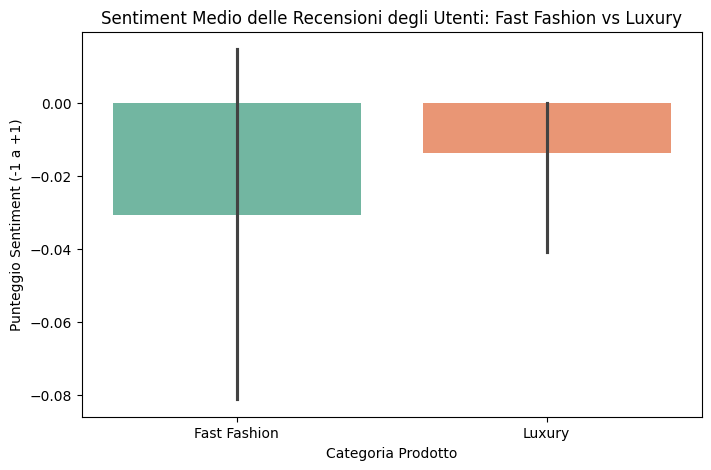

In [ ]:
# Cella 7: Analisi del Sentiment (Vader Sentiment Analyzer)
sia = SentimentIntensityAnalyzer()

# Nota: VADER lavora meglio in inglese, ma fornisce un punteggio di polarità usabile sui termini positivi/negativi
df['sentiment_brand'] = df['descrizione_brand'].apply(lambda x: sia.polarity_scores(x)['compound'])
df['sentiment_recensione'] = df['recensione_utente'].apply(lambda x: sia.polarity_scores(x)['compound'])

# Confronto medie sentiment per Categoria
media_sentiment = df.groupby('categoria')[['sentiment_brand', 'sentiment_recensione']].mean()
print("Punteggio medio del Sentiment per Categoria:")
print(media_sentiment)

# Visualizzazione dei risultati
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='categoria', y='sentiment_recensione', palette='Set2')
plt.title('Sentiment Medio delle Recensioni degli Utenti: Fast Fashion vs Luxury')
plt.ylabel('Punteggio Sentiment (-1 a +1)')
plt.xlabel('Categoria Prodotto')
plt.show()

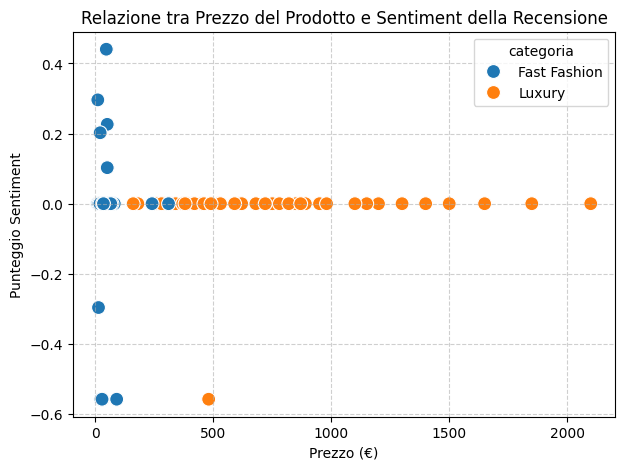

In [ ]:
# Cella 8: Correlazione Prezzo vs Sentiment
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x='prezzo', y='sentiment_recensione', hue='categoria', s=100)
plt.title('Relazione tra Prezzo del Prodotto e Sentiment della Recensione')
plt.xlabel('Prezzo (€)')
plt.ylabel('Punteggio Sentiment')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [ ]:
# Cella 9: Individuazione dei Cluster di Comunicazione tramite K-Means
vectorizer = TfidfVectorizer(max_features=100)
X = vectorizer.fit_transform(df['descrizione_pulita'])

# Eseguiamo K-Means per dividere le descrizioni in 2 cluster
num_cluster = 2
kmeans = KMeans(n_clusters=num_cluster, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X)

print("Parole chiave dominanti per ogni Cluster:")
order_centroids = kmeans.cluster_centers_.argsort()[:, ::-1]
terms = vectorizer.get_feature_names_out()

for i in range(num_cluster):
    top_words = [terms[ind] for ind in order_centroids[i, :5]]
    print(f"--- Cluster {i} ---")
    print(", ".join(top_words))

# Distribuzione del Fast Fashion e Luxury nei Cluster trovati
print("\nMatrice di incrocio (Cluster vs Categoria):")
print(pd.crosstab(df['cluster'], df['categoria']))

Parole chiave dominanti per ogni Cluster:
--- Cluster 0 ---
stile, economica, cotone, pantaloni, seta
--- Cluster 1 ---
lusso, eleganza, mano, pelle, classe

Matrice di incrocio (Cluster vs Categoria):
categoria  Fast Fashion  Luxury
cluster                        
0                    59      26
1                     0      15


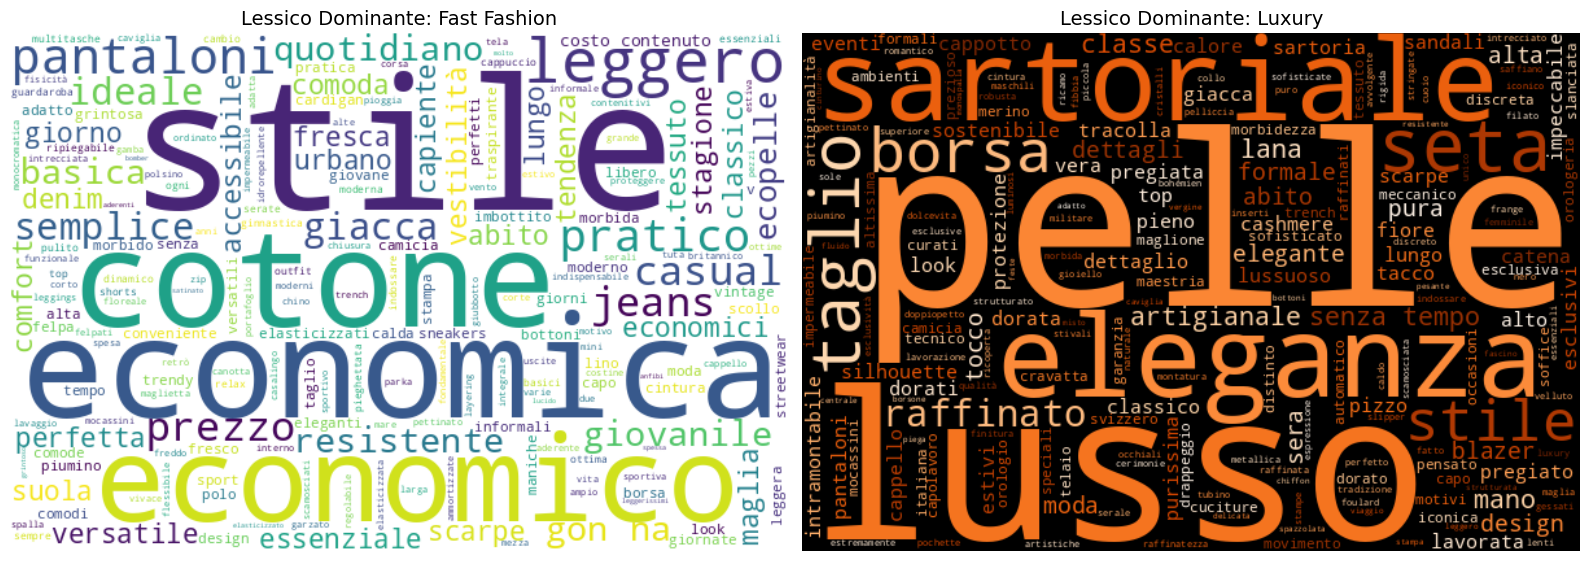

In [ ]:
# Cella 10: Generazione WordCloud per Fast Fashion vs Luxury
testo_fast = " ".join(df[df['categoria'] == 'Fast Fashion']['descrizione_pulita'])
testo_luxury = " ".join(df[df['categoria'] == 'Luxury']['descrizione_pulita'])

wc_fast = WordCloud(width=600, height=400, background_color='white').generate(testo_fast)
wc_luxury = WordCloud(width=600, height=400, background_color='black', colormap='Oranges').generate(testo_luxury)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].imshow(wc_fast, interpolation='bilinear')
axes[0].set_title('Lessico Dominante: Fast Fashion', fontsize=14)
axes[0].axis('off')

axes[1].imshow(wc_luxury, interpolation='bilinear')
axes[1].set_title('Lessico Dominante: Luxury', fontsize=14)
axes[1].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
df.to_csv('dataframe_pulito.csv', index=False)
print("DataFrame esportato con successo in 'dataframe_pulito.csv'")

DataFrame esportato con successo in 'dataframe_pulito.csv'
